In [7]:
# Google Drive 연결

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
# 컬럼 이름 지정

columns = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin",
    "car_name"
]

# 데이터 불러오기
# horsepower의 ? 값은 결측치(NaN)로 처리

df = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/dataset/auto+mpg/auto-mpg.data",
    sep=r"\s+",
    names=columns,
    na_values="?"
)

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [9]:
# 데이터 크기 및 결측치 확인

print("데이터 크기:", df.shape)

print("\n결측치 개수")
print(df.isnull().sum())

데이터 크기: (398, 9)

결측치 개수
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


In [10]:
# 결측치가 있는 행 제거

df = df.dropna()

print("결측치 제거 후 데이터 크기:", df.shape)

결측치 제거 후 데이터 크기: (392, 9)


In [11]:
# car_name은 자동차 이름이므로 학습 데이터에서 제외
# mpg를 예측할 정답(y)으로 사용

X = df.drop(["mpg", "car_name"], axis=1)
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2
)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

학습 데이터: (313, 7)
테스트 데이터: (79, 7)


In [12]:
lr = LinearRegression()

lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

mse_lr = mean_squared_error(y_test, pred_lr)
r2_lr = r2_score(y_test, pred_lr)

print("===== Linear Regression =====")
print("MSE:", mse_lr)
print("R2:", r2_lr)

===== Linear Regression =====
MSE: 11.399115385623777
R2: 0.82209000777022


In [13]:
dt = DecisionTreeRegressor()

dt.fit(X_train, y_train)

pred_dt = dt.predict(X_test)

mse_dt = mean_squared_error(y_test, pred_dt)
r2_dt = r2_score(y_test, pred_dt)

print("===== Decision Tree Regression =====")
print("MSE:", mse_dt)
print("R2:", r2_dt)

===== Decision Tree Regression =====
MSE: 16.513544303797467
R2: 0.7422673216835793


In [14]:
rf = RandomForestRegressor()

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

mse_rf = mean_squared_error(y_test, pred_rf)
r2_rf = r2_score(y_test, pred_rf)

print("===== Random Forest Regression =====")
print("MSE:", mse_rf)
print("R2:", r2_rf)

===== Random Forest Regression =====
MSE: 8.056813936708851
R2: 0.874254478844525


In [15]:
knn = KNeighborsRegressor()

knn.fit(X_train, y_train)

pred_knn = knn.predict(X_test)

mse_knn = mean_squared_error(y_test, pred_knn)
r2_knn = r2_score(y_test, pred_knn)

print("===== KNN Regression =====")
print("MSE:", mse_knn)
print("R2:", r2_knn)

===== KNN Regression =====
MSE: 16.415817721518987
R2: 0.7437925747322268


In [16]:
print("Linear Regression MSE:", mse_lr)
print("Decision Tree MSE:", mse_dt)
print("Random Forest MSE:", mse_rf)
print("KNN MSE:", mse_knn)

Linear Regression MSE: 11.399115385623777
Decision Tree MSE: 16.513544303797467
Random Forest MSE: 8.056813936708851
KNN MSE: 16.415817721518987


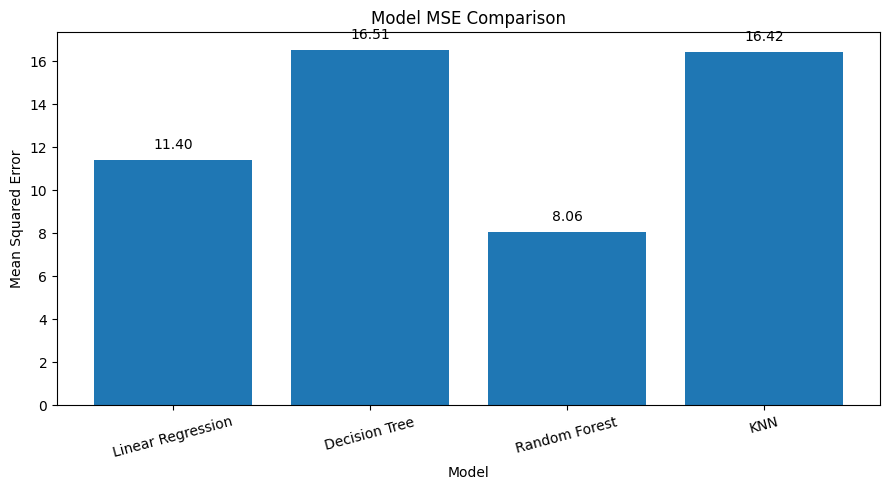

In [17]:
model_names = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "KNN"
]

mse_scores = [
    mse_lr,
    mse_dt,
    mse_rf,
    mse_knn
]

plt.figure(figsize=(9, 5))

plt.bar(model_names, mse_scores)

plt.title("Model MSE Comparison")
plt.xlabel("Model")
plt.ylabel("Mean Squared Error")

for i, score in enumerate(mse_scores):
    plt.text(i, score + 0.5, f"{score:.2f}", ha="center")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

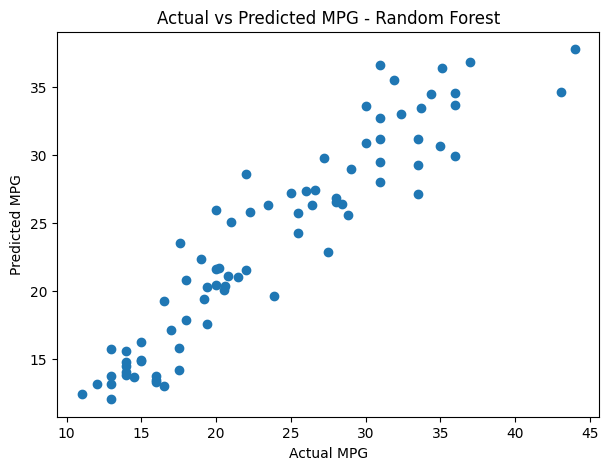

In [18]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, pred_rf)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG - Random Forest")

plt.show()